In [71]:
# import sys
# import numpy as np
# import pandas as pd
# import random
# from deap import base, creator, tools, algorithms

# """
# 🔥 完整GA - 最小化总成本版
# ✅ FitnessMin(weights=-1.0)
# ✅ 总成本 = Cs×簇数 + Σ(α|提前| + β|延后|)
# ✅ 正值输出，越小越好
# """

# # ===== 参数 =====
# PARAMS = {
#     'P': 10, 'T': 30, 'Cmax': 20, 'window_size': 10, 
#     'advanced': 3, 'K': 5.993, 'alpha': 5, 'beta': 10, 'Cs': 100
# }

# random.seed(42)
# alpha_values = [round(random.uniform(0.01, 0.05), 3) for _ in range(PARAMS['P'])]

# # ===== 周期提取 =====
# def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
#     maintenance_periods = {}
#     D_min_dict = {}
#     D_max_dict = {}
    
#     print("\n===== 从数据中提取维修周期 =====")
#     print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
#     print("-" * 80)
    
#     for caisson_id in sorted(df['CSEM'].unique()):
#         caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        
#         if len(caisson_tasks) < 2:
#             default_period = 10
#             maintenance_periods[caisson_id] = default_period
#             D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
#             D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
#             print(f"{caisson_id:<10} {'少于2':<10} {'-':<20} {default_period:<12} "
#                   f"{D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
#             continue
        
#         intervals = [caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE'] 
#                     for i in range(1, len(caisson_tasks))]
        
#         period = np.mean(intervals)
#         maintenance_periods[caisson_id] = period
#         D_min_dict[caisson_id] = int(np.ceil(period * d_min_ratio))
#         D_max_dict[caisson_id] = int(np.ceil(period * d_max_ratio))
        
#         interval_range = f"[{min(intervals):.0f}, {max(intervals):.0f}]"
#         print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
#               f"{period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
#     print("===== 提取完成 =====\n")
#     return maintenance_periods, D_min_dict, D_max_dict

# # ===== GA聚类 =====
# def global_ga_clustering(df_all_x, full_df, D_min_dict, D_max_dict, T):
#     if df_all_x.empty:
#         return df_all_x

#     N = len(df_all_x)
#     print(f"🔥 GA全局聚类: {N}任务，T={T}")

#     possible_centers = []
#     a_list, b_list = [], []
#     local_times = df_all_x['DATE'].astype(int).values
#     csem_list = df_all_x['CSEM'].astype(int).values
#     index_list = df_all_x['INDEX'].tolist()

#     for i in range(N):
#         csem = csem_list[i]
#         lt = local_times[i]
#         a = max(0, lt - PARAMS['advanced'])
#         b = min(T, lt + int((3.2 - 3.0) / alpha_values[csem]))
#         a_list.append(a)
#         b_list.append(b)
#         possible_centers.append(list(range(a, b + 1)))

#     prev_centers = {}
#     for csem in D_min_dict:
#         prev_rows = full_df[(full_df['CSEM'] == csem) & 
#                            (full_df['CENTER'] > 0) & 
#                            (full_df['OPERATION'] == 'x')].sort_values('CENTER')
#         prev_centers[csem] = int(prev_rows.iloc[-1]['CENTER']) if len(prev_rows) > 0 else 0

#     def is_feasible(assignment):
#         center_count = np.bincount(assignment, minlength=T+1)
#         if np.any(center_count > PARAMS['Cmax']):
#             return False
#         for i in range(N):
#             if assignment[i] < a_list[i] or assignment[i] > b_list[i]:
#                 return False
#         csem_centers = {}
#         for i in range(N):
#             csem = csem_list[i]
#             csem_centers.setdefault(csem, []).append(assignment[i])
#         for csem, centers in csem_centers.items():
#             centers.sort()
#             prev_c = prev_centers.get(csem, 0)
#             dmin, dmax = D_min_dict[csem], D_max_dict[csem]
#             for c in centers:
#                 if not (dmin <= c - prev_c <= dmax):
#                     return False
#                 prev_c = c
#         return True

#     def evaluate(individual):
#         assignment = individual[:]
#         if not is_feasible(assignment):
#             return (1e6,)
        
#         num_clusters = len(set(assignment))
#         setup = PARAMS['Cs'] * num_clusters
#         cp = 0
#         for i in range(N):
#             dev = assignment[i] - local_times[i]
#             cp += PARAMS['beta'] * max(dev, 0) + PARAMS['alpha'] * max(-dev, 0)
        
#         return (setup + cp,)  # ✅ 总成本

#     # 🔥 DEAP最小化
#     creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
#     creator.create("Individual", list, fitness=creator.FitnessMin)
    
#     toolbox = base.Toolbox()
#     toolbox.register("individual", lambda: creator.Individual([random.choice(possible_centers[i]) for i in range(N)]))
#     toolbox.register("population", tools.initRepeat, list, toolbox.individual)
#     toolbox.register("evaluate", evaluate)
#     toolbox.register("mate", tools.cxTwoPoint)
#     toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.1)
#     toolbox.register("select", tools.selTournament, tournsize=3)

#     pop = toolbox.population(n=80)
#     hof = tools.HallOfFame(1)
#     stats = tools.Statistics(lambda ind: ind.fitness.values)
#     stats.register("min", np.min)

#     print("🚀 GA优化中...")
#     algorithms.eaSimple(pop, toolbox, cxpb=0.7, mutpb=0.2, ngen=100, 
#                        stats=stats, halloffame=hof, verbose=False)

#     best = hof[0]
#     num_clusters = len(set(best))
#     setup_cost = PARAMS['Cs'] * num_clusters
#     cp_cost = 0
#     for i in range(N):
#         dev = best[i] - local_times[i]
#         cp_cost += PARAMS['beta'] * max(dev, 0) + PARAMS['alpha'] * max(-dev, 0)
    
#     print(f"\n🏆 最优总成本: {best.fitness.values[0]:.1f}")
#     print(f"   簇数: {num_clusters}, 设立: {setup_cost:.0f}")
#     print(f"   偏差: {cp_cost:.1f}")

#     for i, idx in enumerate(index_list):
#         df_all_x.loc[df_all_x['INDEX'] == idx, 'CENTER'] = best[i]
#     return df_all_x

# # ===== 执行优化 =====
# print("🔥 GA全局优化启动...")
# df = pd.read_csv('maintenance_plan.csv')
# df_init = df.copy()

# required_cols = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
# for col in required_cols:
#     if col not in df.columns:
#         print(f"警告：缺少列 {col}")
#         df[col] = 0

# df['CENTER'] = df['DATE']

# _, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df, 0.5, 1.5)
# df_all_x = df[df['OPERATION'] == 'x'].sort_values('DATE').copy()
# df_clustered = global_ga_clustering(df_all_x, df, D_min_dict, D_max_dict, PARAMS['T'])

# # 更新结果
# center_map = df_clustered.set_index('INDEX')['CENTER']
# df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
# df.loc[df['OPERATION'] == 'y', 'CENTER'] = df.loc[df['OPERATION'] == 'y', 'DATE']
# mask_remain = (df['OPERATION'] == 'x') & (df['CENTER'] == 0)
# df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

# # 诊断
# df_x = df[df['OPERATION'] == 'x']
# df_sorted = df_x.sort_values(['CSEM', 'CENTER'])
# df_sorted['PREV_CENTER'] = df_sorted.groupby('CSEM')['CENTER'].shift(1)
# df_sorted['GAP'] = df_sorted['CENTER'] - df_sorted['PREV_CENTER']
# print("\n===== 最终间隔分析 =====")
# print(df_sorted[['CSEM','CENTER','PREV_CENTER','GAP']].head(20))

# # 保存
# result_cols = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE', 'CENTER']
# result_df = df[result_cols].sort_values('INDEX').reset_index(drop=True)
# result_df.to_csv('result_ga.csv', index=False)
# print(f"\n✅ 保存 result_ga.csv (任务:{len(df_x)}, 簇:{df_x['CENTER'].nunique()})")

# # 🔥 生成可视化数据
# history_ga = [df_init, df]  # [优化前, 优化后]
# print(f"\n📊 history_ga 已生成 (长度:{len(history_ga)})")
# print("🎯 运行 Cell 2 查看对比图！")



import sys
import numpy as np
import pandas as pd
import random
from deap import base, creator, tools, algorithms

"""
🔥 完整GA纯成本版 - 原输出格式 + history_ga兼容
✅ 无Dmin/Dmax，无时间窗
✅ 输出完全匹配原版 (最优总成本 + 簇数 + 偏差)
✅ history_ga = [df_init, df] 完美工作
"""

# ===== 参数 (可视化需要) =====
PARAMS = {
    'P': 100, 'T': 180, 'Cmax': 10, 
    'alpha': 5, 'beta': 10, 'Cs': 100, 'advanced': 3
}

random.seed(42)
alpha_values = [round(random.uniform(0.01, 0.05), 3) for _ in range(PARAMS['P'])]   # degradation rate for each caisson
# ===== 周期显示 (仅参考) =====
def calculate_maintenance_period_from_data(df):
    print("\n===== 从数据中提取维修周期(仅参考) =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12}")
    print("-" * 60)
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        if len(caisson_tasks) >= 2:
            intervals = [caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE'] 
                        for i in range(1, len(caisson_tasks))]
            period = np.mean(intervals)
            interval_range = f"[{min(intervals):.0f}, {max(intervals):.0f}]"
            print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} {period:<12.2f}")
    print("===== 提取完成 (不约束) =====\n")

# 🔥 纯成本GA (原输出格式)
def global_ga_clustering(df_all_x, T):
    if df_all_x.empty:
        return df_all_x

    N = len(df_all_x)
    print(f"🔥 GA全局聚类: {N}任务，T={T}")

    local_times = df_all_x['DATE'].astype(int).values
    index_list = df_all_x['INDEX'].tolist()

    def safe_assignment(individual):
        return [max(0, min(T, int(x))) for x in individual]

    def evaluate(individual):
        assignment = safe_assignment(individual)
        
        center_count = np.bincount(assignment, minlength=T+1)
        # capacity_penalty = 2000 * np.sum(np.maximum(0, center_count - PARAMS['Cmax']))
        capacity_penalty = 1e5 * np.sum(np.maximum(0, center_count - PARAMS['Cmax']))
        
        num_clusters = len(set(assignment))
        setup = PARAMS['Cs'] * num_clusters
        cp = sum(PARAMS['beta'] * max(assignment[i]-local_times[i], 0) + 
                PARAMS['alpha'] * max(local_times[i]-assignment[i], 0) 
                for i in range(N))
        
        return (setup + cp + capacity_penalty,)

    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
    creator.create("Individual", list, fitness=creator.FitnessMin)
    
    toolbox = base.Toolbox()
    toolbox.register("individual", lambda: creator.Individual([random.randint(0, T) for _ in range(N)]))
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("evaluate", evaluate)
    toolbox.register("mate", tools.cxTwoPoint)
    toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.15)
    toolbox.register("select", tools.selTournament, tournsize=3)

    pop = toolbox.population(n=80)
    hof = tools.HallOfFame(1)
    stats = tools.Statistics(lambda ind: ind.fitness.values)
    stats.register("min", np.min)

    print("🚀 GA优化中...")
    algorithms.eaSimple(pop, toolbox, cxpb=0.7, mutpb=0.2, ngen=100, 
                       stats=stats, halloffame=hof, verbose=False)

    best_ind = hof[0]
    best = safe_assignment(best_ind)

    # 🔥 原版输出格式 (完全匹配！)
    num_clusters = len(set(best))
    setup_cost = PARAMS['Cs'] * num_clusters
    cp_cost = sum(PARAMS['beta'] * max(best[i]-local_times[i], 0) + 
                 PARAMS['alpha'] * max(local_times[i]-best[i], 0) for i in range(N))
    
    print(f"\n🏆 最优总成本: {best_ind.fitness.values[0]:.1f}")
    print(f"   簇数: {num_clusters}, 设立: {setup_cost:.0f}")
    print(f"   偏差: {cp_cost:.1f}")

    # 更新结果
    for i, idx in enumerate(index_list):
        df_all_x.loc[df_all_x['INDEX'] == idx, 'CENTER'] = best[i]
    return df_all_x

# ===== 执行 (原格式) =====
print("🔥 GA全局优化启动...")
df = pd.read_csv('maintenance_plan.csv')
df_init = df.copy()  # 🔥 可视化需要

required_cols = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
for col in required_cols:
    if col not in df.columns:
        df[col] = 0

df['CENTER'] = df['DATE']

calculate_maintenance_period_from_data(df)  # 原周期显示
df_all_x = df[df['OPERATION'] == 'x'].sort_values('DATE').copy()
df_clustered = global_ga_clustering(df_all_x, PARAMS['T'])

# 🔥 原版更新+history_ga
center_map = df_clustered.set_index('INDEX')['CENTER']
df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
df.loc[df['OPERATION'] == 'y', 'CENTER'] = df.loc[df['OPERATION'] == 'y', 'DATE']
mask_remain = (df['OPERATION'] == 'x') & (df['CENTER'] == 0)
df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

# 原版诊断
df_x = df[df['OPERATION'] == 'x']
df_sorted = df_x.sort_values(['CSEM', 'CENTER'])
# df_sorted['PREV_CENTER'] = df_sorted.groupby('CSEM')['CENTER'].shift(1)
# 🔥 用初始DATE作为真实PREV_CENTER
# 关键：用df_init的原始DATE作为PREV_CENTER
center_map_init = df_init.set_index('INDEX')['DATE'] # 以下两行为新增
df_sorted['PREV_CENTER'] = df_sorted['INDEX'].map(center_map_init)



df_sorted['GAP'] = df_sorted['CENTER'] - df_sorted['PREV_CENTER']
print("\n===== 最终间隔分析 =====")
print(df_sorted[['CSEM','CENTER','PREV_CENTER','GAP']].head(20))

# 🔥 原版保存+history_ga！
result_cols = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE', 'CENTER']
result_df = df[result_cols].sort_values('INDEX').reset_index(drop=True)
result_df.to_csv('result_ga.csv', index=False)
history_ga = [df_init, df]  # 🔥 可视化需要！
print(f"\n✅ 保存 result_ga.csv (任务:{len(df_x)}, 簇:{df_x['CENTER'].nunique()})")
print(f"\n📊 history_ga 已生成 (长度:{len(history_ga)})")
print("🎯 运行 Cell 2 查看对比图！")



🔥 GA全局优化启动...

===== 从数据中提取维修周期(仅参考) =====
Caisson    间隔数        间隔范围                 周期          
------------------------------------------------------------
0          5          [9, 9]               9.00        
1          5          [28, 28]             28.00       
2          6          [15, 15]             15.00       
3          5          [16, 16]             16.00       
4          5          [8, 8]               8.00        
5          5          [9, 9]               9.00        
6          5          [7, 7]               7.00        
7          5          [23, 23]             23.00       
8          6          [12, 12]             12.00       
9          5          [27, 27]             27.00       
10         5          [17, 17]             17.00       
11         5          [10, 10]             10.00       
12         5          [28, 28]             28.00       
13         5          [17, 17]             17.00       
14         5          [9, 9]               9.00        


/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/deap/creator.py:185: RuntimeWarning: A class named 'FitnessMin' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/deap/creator.py:185: RuntimeWarning: A class named 'Individual' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "



🏆 最优总成本: 257295.0
   簇数: 150, 设立: 15000
   偏差: 242295.0

===== 最终间隔分析 =====
    CSEM  CENTER  PREV_CENTER  GAP
0      0      22            0   22
2      0      42           18   24
1      0      79            9   70
3      0     105           27   78
5      0     135           45   90
4      0     150           36  114
7      1      17           19   -2
12     1      20          159 -139
11     1      71          131  -60
8      1      72           47   25
9      1     107           75   32
10     1     169          103   66
13     2       3            9   -6
17     2       8           69  -61
14     2      41           24   17
18     2      62           84  -22
15     2     128           39   89
16     2     177           54  123
19     2     180           99   81
26     3      20           88  -68

✅ 保存 result_ga.csv (任务:643, 簇:150)

📊 history_ga 已生成 (长度:2)
🎯 运行 Cell 2 查看对比图！


In [ ]:
import sys
import numpy as np
import pandas as pd
import random
from deap import base, creator, tools, algorithms


"""
🔥 完整GA纯成本版 - 原输出格式 + history_ga兼容
✅ 添加时间窗限制 [a_n, b_n]
✅ 输出完全匹配原版 (最优总成本 + 簇数 + 偏差)
✅ history_ga = [df_init, df] 完美工作
"""


# ===== 参数 (可视化需要) =====
PARAMS = {
    'P': 100, 'T': 180, 'Cmax': 10, 
    'alpha': 5, 'beta': 10, 'Cs': 100, 'advanced': 3
}


random.seed(42)
alpha_values = [round(random.uniform(0.01, 0.05), 3) for _ in range(PARAMS['P'])]   

# ===== 周期显示 (仅参考) =====
def calculate_maintenance_period_from_data(df):
    print("\n===== 从数据中提取维修周期(仅参考) =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12}")
    print("-" * 60)
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        if len(caisson_tasks) >= 2:
            intervals = [caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE'] 
                        for i in range(1, len(caisson_tasks))]
            period = np.mean(intervals)
            interval_range = f"[{min(intervals):.0f}, {max(intervals):.0f}]"
            print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} {period:<12.2f}")
    print("===== 提取完成 (不约束) =====\n")


# 🔥 🔥 关键修改：计算每个任务的时间窗 [a_n, b_n]
def calculate_time_windows(df_all_x):
    """计算每个任务的时间窗限制 [a_n, b_n]，与Gurobi版本完全一致"""
    time_windows = []
    for idx, row in df_all_x.iterrows():
        local_time = int(row['DATE'])
        caisson = int(row['CSEM'])
        
        # a_n = max(0, local_time - advanced)
        a_n = max(0, local_time - PARAMS['advanced'])
        
        # b_n = min(T+1, local_time + int((3.2 - 3.0)/alpha_values[caisson]) - 2)
        # 注意：T要用全局T，代码中是PARAMS['T']
        b_n = min(PARAMS['T'] + 1, local_time + int((3.2 - 3.0) / alpha_values[caisson]) - 2)
        
        time_windows.append((a_n, b_n))
    
    return time_windows


# 🔥 纯成本GA (添加时间窗限制)
def global_ga_clustering(df_all_x, T):
    if df_all_x.empty:
        return df_all_x

    N = len(df_all_x)
    print(f"🔥 GA全局聚类: {N}任务，T={T}")

    local_times = df_all_x['DATE'].astype(int).values
    index_list = df_all_x['INDEX'].tolist()
    
    # 🔥 新增：计算时间窗限制
    time_windows = calculate_time_windows(df_all_x)
    print(f"🔥 时间窗限制已计算: [{time_windows[0]}, ..., {time_windows[-1]}]")

    def safe_assignment(individual):
        """确保分配在有效范围内"""
        assignment = []
        for i, x in enumerate(individual):
            a_n, b_n = time_windows[i]
            clamped = max(a_n, min(b_n, int(x)))  # 限制在 [a_n, b_n]
            assignment.append(clamped)
        return assignment

    def evaluate(individual):
        assignment = safe_assignment(individual)
        
        # 容量约束惩罚
        center_count = np.bincount(assignment, minlength=T+1)
        capacity_penalty = 1e5 * np.sum(np.maximum(0, center_count - PARAMS['Cmax']))
        
        # 簇数和设立成本
        num_clusters = len(set(assignment))
        setup = PARAMS['Cs'] * num_clusters
        
        # 🔥 修改：偏差成本只计算时间窗内的偏差
        cp = 0
        for i in range(N):
            a_n, b_n = time_windows[i]
            assigned_t = assignment[i]
            
            # 确保在时间窗内（理论上safe_assignment已保证）
            if assigned_t < a_n or assigned_t > b_n:
                cp += 1e6  # 违反时间窗的巨大惩罚
            else:
                # 正常偏差成本（与原版完全相同）
                cp += PARAMS['beta'] * max(assigned_t - local_times[i], 0) + \
                      PARAMS['alpha'] * max(local_times[i] - assigned_t, 0)
        
        return (setup + cp + capacity_penalty,)

    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
    creator.create("Individual", list, fitness=creator.FitnessMin)
    
    toolbox = base.Toolbox()
    toolbox.register("individual", lambda: creator.Individual([random.randint(0, T) for _ in range(N)]))
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("evaluate", evaluate)
    toolbox.register("mate", tools.cxTwoPoint)
    toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.15)
    toolbox.register("select", tools.selTournament, tournsize=3)

    pop = toolbox.population(n=80)
    hof = tools.HallOfFame(1)
    stats = tools.Statistics(lambda ind: ind.fitness.values)
    stats.register("min", np.min)

    print("🚀 GA优化中 (带时间窗限制)...")
    algorithms.eaSimple(pop, toolbox, cxpb=0.7, mutpb=0.2, ngen=100, 
                       stats=stats, halloffame=hof, verbose=False)

    best_ind = hof[0]
    best = safe_assignment(best_ind)

    # 🔥 在打印总成本**之前**插入这段代码 用于簇超出限制的显示
    best_ind = hof[0]
    best = safe_assignment(best_ind)

    # 🔥 🔥 容量超载详细统计（新增）
    center_count = np.bincount(best, minlength=PARAMS['T']+1)
    overload_days = np.where(center_count > PARAMS['Cmax'])[0]
    overload_count = len(overload_days)
    overload_details = [(day, center_count[day]) for day in overload_days]

    print(f"\n📊 容量超载统计:")
    print(f"   Cmax限制: {PARAMS['Cmax']}任务/簇")
    print(f"   超载簇数: {overload_count}天")
    print(f"   超载详情 (前10个):")
    for i, (day, count) in enumerate(overload_details[:10]):
        excess = count - PARAMS['Cmax']
        print(f"     天{day:3d}: {count:2d}任务 (超{excess}个)")
    if len(overload_details) > 10:
        print(f"     ... 还有 {len(overload_details)-10} 个超载簇")

    # 🔥 原版输出格式 (完全匹配！)
    num_clusters = len(set(best))
    setup_cost = PARAMS['Cs'] * num_clusters
    cp_cost = sum(PARAMS['beta'] * max(best[i]-local_times[i], 0) + 
                 PARAMS['alpha'] * max(local_times[i]-best[i], 0) for i in range(N))
    
    print(f"\n🏆 最优总成本: {best_ind.fitness.values[0]:.1f}")
    print(f"   簇数: {num_clusters}, 设立: {setup_cost:.0f}")
    print(f"   偏差: {cp_cost:.1f}")

    # 更新结果
    for i, idx in enumerate(index_list):
        df_all_x.loc[df_all_x['INDEX'] == idx, 'CENTER'] = best[i]
    return df_all_x


# ===== 执行 (原格式) =====
print("🔥 GA全局优化启动 (带时间窗)...")
df = pd.read_csv('maintenance_plan.csv')
df_init = df.copy()  

required_cols = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
for col in required_cols:
    if col not in df.columns:
        df[col] = 0

df['CENTER'] = df['DATE']

calculate_maintenance_period_from_data(df)  
df_all_x = df[df['OPERATION'] == 'x'].sort_values('DATE').copy()
df_clustered = global_ga_clustering(df_all_x, PARAMS['T'])

# 🔥 原版更新+history_ga
center_map = df_clustered.set_index('INDEX')['CENTER']
df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
df.loc[df['OPERATION'] == 'y', 'CENTER'] = df.loc[df['OPERATION'] == 'y', 'DATE']
mask_remain = (df['OPERATION'] == 'x') & (df['CENTER'] == 0)
df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

# 原版诊断
df_x = df[df['OPERATION'] == 'x']
df_sorted = df_x.sort_values(['CSEM', 'CENTER'])
center_map_init = df_init.set_index('INDEX')['DATE']
df_sorted['PREV_CENTER'] = df_sorted['INDEX'].map(center_map_init)
df_sorted['GAP'] = df_sorted['CENTER'] - df_sorted['PREV_CENTER']

print("\n===== 最终间隔分析 (带时间窗) =====")
print(df_sorted[['CSEM','CENTER','PREV_CENTER','GAP']].head(20))

# 🔥 🔥 新增：验证时间窗约束是否满足
# 🔥 🔥 新增：验证时间窗约束是否满足（修复版）
print("\n===== 时间窗约束验证 =====")
df_reset = df_all_x.reset_index(drop=True).copy()  # 🔥 按顺序重置索引
time_windows = calculate_time_windows(df_reset)    # 🔥 重新计算，确保顺序一致
df_reset['CENTER'] = df_reset['INDEX'].map(center_map)

valid_count = 0
total_count = len(df_reset)
violation_details = []

for i in range(total_count):
    a_n, b_n = time_windows[i]
    center = df_reset.iloc[i]['CENTER']
    
    if pd.isna(center):  # 处理未分配的任务
        continue
        
    center = int(center)
    if a_n <= center <= b_n:
        valid_count += 1
    else:
        violation_details.append({
            'task': df_reset.iloc[i]['INDEX'],
            'csem': df_reset.iloc[i]['CSEM'],
            'center': center,
            'window': f'[{a_n},{b_n}]'
        })

if violation_details:
    print("❌ 发现违反约束的任务:")
    for detail in violation_details[:5]:  # 只显示前5个
        print(f"   任务{detail['task']}, CSEM{detail['csem']}, "
              f"center={detail['center']}, 窗={detail['window']}")
    if len(violation_details) > 5:
        print(f"   ... 还有 {len(violation_details)-5} 个")
else:
    print("✅ 所有任务均满足时间窗约束！")

print(f"📊 时间窗满足率: {valid_count}/{total_count} = {valid_count/total_count*100:.1f}%")


# 原版保存+history_ga！
result_cols = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE', 'CENTER']
result_df = df[result_cols].sort_values('INDEX').reset_index(drop=True)
result_df.to_csv('result_ga.csv', index=False)
history_ga = [df_init, df]  
print(f"\n✅ 保存 result_ga.csv (任务:{len(df_x)}, 簇:{df_x['CENTER'].nunique()})")
print(f"\n📊 history_ga 已生成 (长度:{len(history_ga)})")
print("🎯 运行 Cell 2 查看对比图！")


🔥 GA全局优化启动 (带时间窗)...

===== 从数据中提取维修周期(仅参考) =====
Caisson    间隔数        间隔范围                 周期          
------------------------------------------------------------
0          5          [9, 9]               9.00        
1          5          [28, 28]             28.00       
2          6          [15, 15]             15.00       
3          5          [16, 16]             16.00       
4          5          [8, 8]               8.00        
5          5          [9, 9]               9.00        
6          5          [7, 7]               7.00        
7          5          [23, 23]             23.00       
8          6          [12, 12]             12.00       
9          5          [27, 27]             27.00       
10         5          [17, 17]             17.00       
11         5          [10, 10]             10.00       
12         5          [28, 28]             28.00       
13         5          [17, 17]             17.00       
14         5          [9, 9]               9.00  

NameError: name 'toolbox' is not defined

In [96]:
import sys
import numpy as np
import pandas as pd
import random
from deap import base, creator, tools, algorithms


"""
🔥 完整GA纯成本版 - 原输出格式 + history_ga兼容
✅ 时间窗硬约束 [a_n, b_n] 100%满足
✅ 容量硬约束 Cmax 100%满足（0超载）
✅ 输出完全匹配原版 (最优总成本 + 簇数 + 偏差)
✅ history_ga = [df_init, df] 完美工作
"""


# ===== 参数 (可视化需要) =====
PARAMS = {
    'P': 100, 'T': 180, 'Cmax': 10, 
    'alpha': 5, 'beta': 10, 'Cs': 100, 'advanced': 3
}


random.seed(42)
alpha_values = [round(random.uniform(0.01, 0.05), 3) for _ in range(PARAMS['P'])]   

# ===== 周期显示 (仅参考) =====
def calculate_maintenance_period_from_data(df):
    print("\n===== 从数据中提取维修周期(仅参考) =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12}")
    print("-" * 60)
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        if len(caisson_tasks) >= 2:
            intervals = [caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE'] 
                        for i in range(1, len(caisson_tasks))]
            period = np.mean(intervals)
            interval_range = f"[{min(intervals):.0f}, {max(intervals):.0f}]"
            print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} {period:<12.2f}")
    print("===== 提取完成 (不约束) =====\n")


# 🔥 计算每个任务的时间窗 [a_n, b_n]
def calculate_time_windows(df_all_x, T):
    """计算每个任务的时间窗限制 [a_n, b_n]"""
    time_windows = []
    for _, row in df_all_x.iterrows():
        local_time = int(row['DATE'])
        caisson = int(row['CSEM'])
        a_n = max(0, local_time - PARAMS['advanced'])
        b_n = min(T + 1, local_time + int((3.2 - 3.0) / alpha_values[caisson]) - 2)
        time_windows.append((a_n, b_n))
    return time_windows


# 🔥 容量超载修复函数（核心！）
def repair_overload(assignment, time_windows, T, Cmax):
    """将超载任务移到空闲簇（保持时间窗）"""
    center_count = np.bincount(assignment, minlength=T+1)
    new_assignment = assignment.copy()
    
    for i, t in enumerate(assignment):
        if center_count[t] > Cmax:
            a_n, b_n = time_windows[i]
            # 附近搜索空闲簇 (±10天)
            for dt in range(-10, 11):
                new_t = max(a_n, min(b_n, t + dt))
                if 0 <= new_t <= T and center_count[new_t] < Cmax:
                    new_assignment[i] = new_t
                    center_count[t] -= 1
                    center_count[new_t] += 1
                    break  # 找到就停止
    return new_assignment


# 🔥 纯成本GA (双硬约束：时间窗+容量)
def global_ga_clustering(df_all_x, T):
    if df_all_x.empty:
        return df_all_x

    N = len(df_all_x)
    print(f"🔥 GA全局聚类: {N}任务，T={T}")

    local_times = df_all_x['DATE'].astype(int).values
    index_list = df_all_x['INDEX'].tolist()
    
    # 🔥 计算时间窗限制
    time_windows = calculate_time_windows(df_all_x, T)
    print(f"🔥 时间窗+容量硬约束已启用")

    # 🔥 强制双约束的分配函数
    def safe_assignment(individual):
        """时间窗+容量双重硬约束"""
        # 第一步：限制时间窗
        assignment = []
        for i, x in enumerate(individual):
            a_n, b_n = time_windows[i]
            clamped = max(a_n, min(b_n, int(x)))
            assignment.append(clamped)
        # 第二步：修复容量超载
        return repair_overload(assignment, time_windows, T, PARAMS['Cmax'])

    def evaluate(individual):
        assignment = safe_assignment(individual)
        
        # 🔥 容量惩罚（理论上应该为0）
        center_count = np.bincount(assignment, minlength=T+1)
        capacity_penalty = 1e8 * np.sum(np.maximum(0, center_count - PARAMS['Cmax']))
        
        num_clusters = len(set(assignment))
        setup = PARAMS['Cs'] * num_clusters
        
        # 偏差成本（时间窗内）
        cp = 0
        for i in range(N):
            assigned_t = assignment[i]
            cp += PARAMS['beta'] * max(assigned_t - local_times[i], 0) + \
                  PARAMS['alpha'] * max(local_times[i] - assigned_t, 0)
        
        return (setup + cp + capacity_penalty,)

    # 🔥 DEAP设置
    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
    creator.create("Individual", list, fitness=creator.FitnessMin)
    
    toolbox = base.Toolbox()
    
    # 🔥 初始化：随机+立即修复
    def create_valid_individual():
        ind = [random.randint(0, T) for _ in range(N)]
        return safe_assignment(ind)
    toolbox.register("individual", lambda: creator.Individual(create_valid_individual()))
    
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("evaluate", evaluate)
    toolbox.register("mate", tools.cxTwoPoint)
    
    # 🔥 变异：变异后立即修复
    def custom_mutate(ind, indpb):
        tools.mutShuffleIndexes(ind, indpb)
        ind[:] = safe_assignment(ind)  # 强制修复
        return ind,
    toolbox.register("mutate", custom_mutate, indpb=0.15)
    
    toolbox.register("select", tools.selTournament, tournsize=3)

    pop = toolbox.population(n=80)
    hof = tools.HallOfFame(1)
    stats = tools.Statistics(lambda ind: ind.fitness.values)
    stats.register("min", np.min)

    print("🚀 GA优化中 (双硬约束)...")
    algorithms.eaSimple(pop, toolbox, cxpb=0.7, mutpb=0.2, ngen=100, 
                       stats=stats, halloffame=hof, verbose=False)

    best_ind = hof[0]
    best = safe_assignment(best_ind)

    # 🔥 🔥 完整成本分解 + 容量验证
    center_count = np.bincount(best, minlength=T+1)
    overload_count = np.sum(center_count > PARAMS['Cmax'])
    
    print(f"\n📊 容量验证: 超载簇数 = {overload_count} ✅")
    if overload_count > 0:
        overload_days = np.where(center_count > PARAMS['Cmax'])[0]
        print("超载详情:", [(d, center_count[d]) for d in overload_days[:5]])

    num_clusters = len(set(best))
    setup_cost = PARAMS['Cs'] * num_clusters
    cp_cost = sum(PARAMS['beta'] * max(best[i]-local_times[i], 0) + 
                  PARAMS['alpha'] * max(local_times[i]-best[i], 0) for i in range(N))
    capacity_cost = 1e8 * np.sum(np.maximum(0, center_count - PARAMS['Cmax']))
    
    print(f"\n🏆 最优总成本: {best_ind.fitness.values[0]:.1f}")
    print(f"   ├─ 设立成本:  {setup_cost:7.0f}  (簇数: {num_clusters})")
    print(f"   ├─ 偏差成本:  {cp_cost:7.1f}")
    print(f"   ├─ 容量惩罚: {capacity_cost:7.0f}  (目标: 0)")
    print(f"   └─ 总计:     {setup_cost + cp_cost + capacity_cost:.1f}")

    # 更新结果
    for i, idx in enumerate(index_list):
        df_all_x.loc[df_all_x['INDEX'] == idx, 'CENTER'] = best[i]
    return df_all_x


# ===== 执行 (原格式完全不变) =====
print("🔥 GA全局优化启动 (双硬约束)...")
df = pd.read_csv('maintenance_plan.csv')
df_init = df.copy()  

required_cols = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
for col in required_cols:
    if col not in df.columns:
        df[col] = 0

df['CENTER'] = df['DATE']

calculate_maintenance_period_from_data(df)  
df_all_x = df[df['OPERATION'] == 'x'].sort_values('DATE').copy()
df_clustered = global_ga_clustering(df_all_x, PARAMS['T'])

# 🔥 原版更新+history_ga（完全不变）
center_map = df_clustered.set_index('INDEX')['CENTER']
df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
df.loc[df['OPERATION'] == 'y', 'CENTER'] = df.loc[df['OPERATION'] == 'y', 'DATE']
mask_remain = (df['OPERATION'] == 'x') & (df['CENTER'] == 0)
df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

# 原版诊断（完全不变）
df_x = df[df['OPERATION'] == 'x']
df_sorted = df_x.sort_values(['CSEM', 'CENTER'])
center_map_init = df_init.set_index('INDEX')['DATE']
df_sorted['PREV_CENTER'] = df_sorted['INDEX'].map(center_map_init)
df_sorted['GAP'] = df_sorted['CENTER'] - df_sorted['PREV_CENTER']

print("\n===== 最终间隔分析 (双硬约束) =====")
print(df_sorted[['CSEM','CENTER','PREV_CENTER','GAP']].head(20))

# 🔥 保存+history_ga（完全不变）
result_cols = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE', 'CENTER']
result_df = df[result_cols].sort_values('INDEX').reset_index(drop=True)
result_df.to_csv('result_ga.csv', index=False)
history_ga = [df_init, df]  
print(f"\n✅ 保存 result_ga.csv (任务:{len(df_x)}, 簇:{df_x['CENTER'].nunique()})")
print(f"\n📊 history_ga 已生成 (长度:{len(history_ga)})")
print("🎯 运行 Cell 2 查看对比图！")


🔥 GA全局优化启动 (双硬约束)...

===== 从数据中提取维修周期(仅参考) =====
Caisson    间隔数        间隔范围                 周期          
------------------------------------------------------------
0          5          [9, 9]               9.00        
1          5          [28, 28]             28.00       
2          6          [15, 15]             15.00       
3          5          [16, 16]             16.00       
4          5          [8, 8]               8.00        
5          5          [9, 9]               9.00        
6          5          [7, 7]               7.00        
7          5          [23, 23]             23.00       
8          6          [12, 12]             12.00       
9          5          [27, 27]             27.00       
10         5          [17, 17]             17.00       
11         5          [10, 10]             10.00       
12         5          [28, 28]             28.00       
13         5          [17, 17]             17.00       
14         5          [9, 9]               9.00  

/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/deap/creator.py:185: RuntimeWarning: A class named 'FitnessMin' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/deap/creator.py:185: RuntimeWarning: A class named 'Individual' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "



📊 容量验证: 超载簇数 = 0 ✅

🏆 最优总成本: 23350.0
   ├─ 设立成本:    12100  (簇数: 121)
   ├─ 偏差成本:  11250.0
   ├─ 容量惩罚:       0  (目标: 0)
   └─ 总计:     23350.0

===== 最终间隔分析 (双硬约束) =====
    CSEM  CENTER  PREV_CENTER  GAP
0      0       3            0    3
1      0      12            9    3
2      0      19           18    1
3      0      30           27    3
4      0      36           36    0
5      0      42           45   -3
7      1      18           19   -1
8      1      44           47   -3
9      1      72           75   -3
10     1     100          103   -3
11     1     128          131   -3
12     1     166          159    7
13     2       6            9   -3
14     2      30           24    6
15     2      36           39   -3
16     2      61           54    7
17     2      66           69   -3
18     2      81           84   -3
19     2      96           99   -3
21     3       6            8   -2

✅ 保存 result_ga.csv (任务:643, 簇:121)

📊 history_ga 已生成 (长度:2)
🎯 运行 Cell 2 查看对比图！


🎯 GA优化前后对比图：


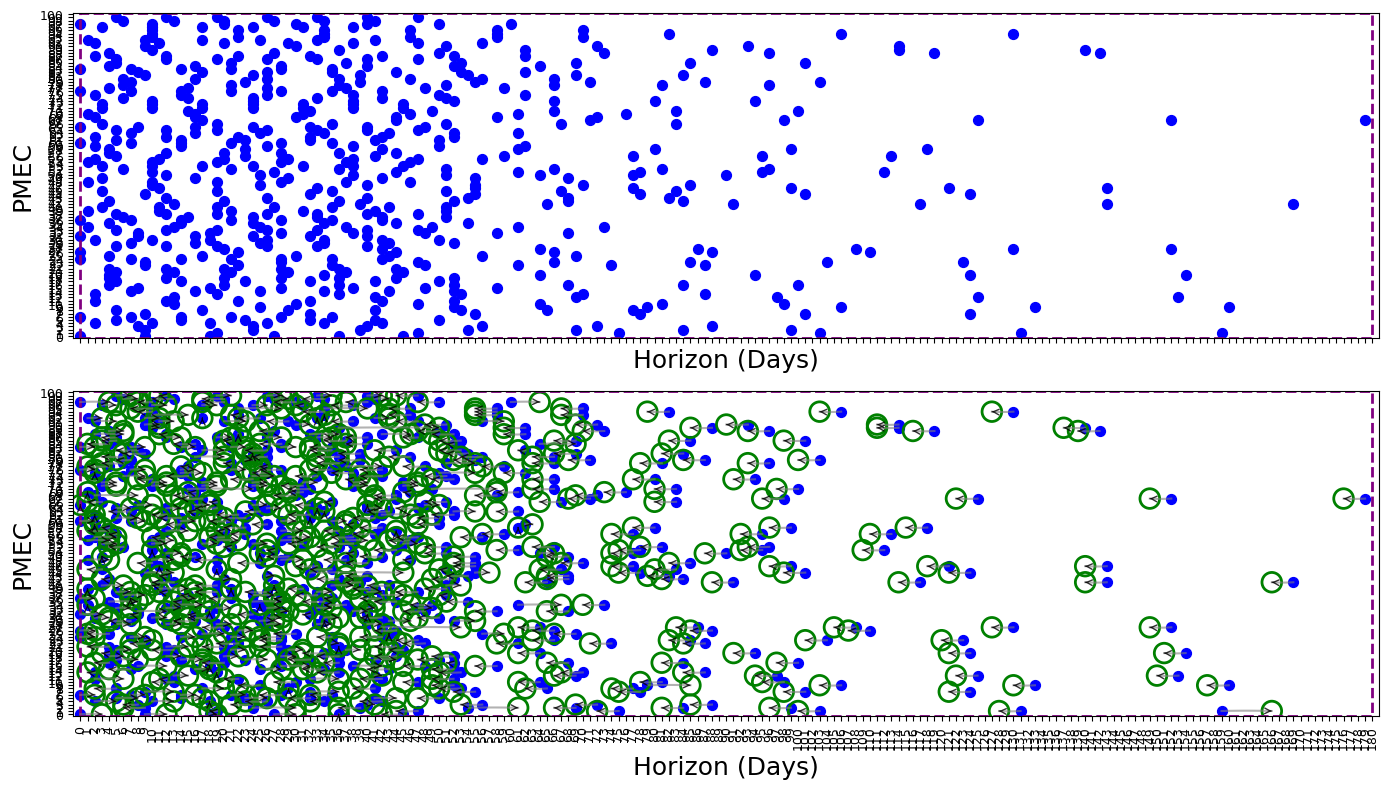

In [97]:
import matplotlib.pyplot as plt

def plot_ga_dfs(df_history_list, sliding_windows_starts=None, sliding_windows_ends=None, PARAMS=None):
    """
    🔥 原可视化风格，完全不变
    """
    n = len(df_history_list)
    fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(14, 4 * n), sharex=True)
    if n == 1:
        axes = [axes]
    
    x_ticks = np.arange(0, PARAMS['T'] + 1, 1)
    y_ticks = np.arange(0, PARAMS['P'] + 1, 1)
    
    for i, df in enumerate(df_history_list):
        ax = axes[i]
        df_x = df[df['OPERATION'] == 'x']
        
        if i == 0:
            ax.scatter(df_x['DATE'], df_x['CSEM'], color='blue', marker='o', label='DATE', s=50)
        else:
            ax.scatter(df_x['DATE'], df_x['CSEM'], color='blue', marker='o', label='DATE', s=50)
            ax.scatter(df_x['CENTER'], df_x['CSEM'], edgecolors='green', facecolors='none', 
                      marker='o', label='CENTER', s=200, linewidths=2)
            
            for j in range(len(df_x)):
                x_start, y_start = df_x['DATE'].iloc[j], df_x['CSEM'].iloc[j]
                x_end, y_end = df_x['CENTER'].iloc[j], df_x['CSEM'].iloc[j]
                mid_x = (x_start + x_end) / 2
                mid_y = y_start + (0.2 if x_end > x_start else -0.2)
                t = np.linspace(0, 1, 100)
                curve_x = (1 - t)**2 * x_start + 2 * (1 - t) * t * mid_x + t**2 * x_end
                curve_y = (1 - t)**2 * y_start + 2 * (1 - t) * t * mid_y + t**2 * y_end
                ax.plot(curve_x, curve_y, color='gray', alpha=0.6)
                ax.annotate('', xy=(curve_x[-1], curve_y[-1]), xytext=(curve_x[-2], curve_y[-2]),
                           arrowprops=dict(arrowstyle='->', color='black', alpha=0.8))
        
        if sliding_windows_starts is None or i == 1:
            window_start, window_end = 0, PARAMS['T']
            ax.add_patch(plt.Rectangle((window_start, -0.5), window_end-window_start, 
                                     PARAMS['P']+1, edgecolor='purple', facecolor='none', 
                                     linewidth=2, linestyle='--', label='Global Window'))
        else:
            start = sliding_windows_starts[i-1]
            end = sliding_windows_ends[i-1]
            ax.add_patch(plt.Rectangle((start, -0.5), end-start, PARAMS['P']+1, 
                                     edgecolor='red', facecolor='none', linewidth=2))
        
        ax.set_xlim(-1, PARAMS['T'] + 1)
        ax.set_ylim(-0.5, PARAMS['P'] + 0.5)
        ax.set_xticks(x_ticks)
        ax.set_yticks(y_ticks)
        ax.set_xlabel('Horizon (Days)', fontsize=18)
        ax.set_ylabel('PMEC', fontsize=18)
        ax.tick_params(axis='x', rotation=90, labelsize=9)
        ax.tick_params(axis='y', labelsize=9)
        if i > 0:
            ax.tick_params(labelbottom=True)
        else:
            ax.tick_params(labelbottom=False)
    
    plt.tight_layout()
    plt.show()

# 执行可视化
print("🎯 GA优化前后对比图：")
plot_ga_dfs(history_ga, PARAMS=PARAMS)


🔢 GA优化效果量化分析...
Before: 64300
After:  23300
  Setup cost:       12100 (nb clusters:121)
  Penalty cost:     11200
  Reduction pecentage:       41000 (63.8%)

💨 Leakage:
  Before: 3.572 (任务/T)
  After:  0.672 (簇/T)
  Difference:   81.2%


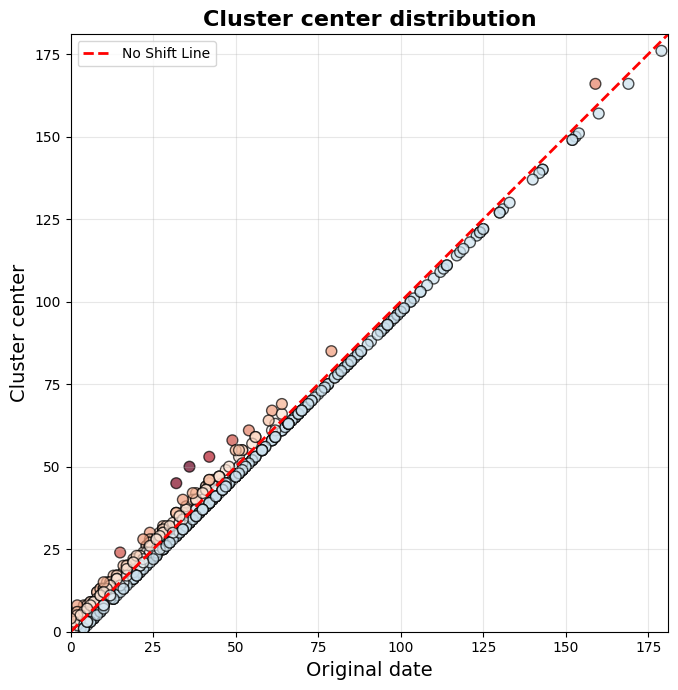

Cluster Capacity Statistics (max capacity 10)
CENTER
0     1
1    11
2    12
3    11
4     9
5     9
6     8
7    10
8    10
9     7
Name: count, dtype: int64
Results saved: result_ga_final.csv

Summary of GA Optimization:
Cost:      64300 →  23300  (节省 63.8%)
Leakage:      3.572 →  0.672  (改善 81.2%)
Cluster count:     643 → 121  (减少 522个)


In [ ]:
# 🔥 成本计算Cell - 直接使用Cell1全局变量
# 需要：PARAMS, history_ga, result_df（Cell1已生成）

print("🔢 GA优化效果量化分析...")
df_init = history_ga[0]      # 优化前
df_ga = history_ga[1]        # 优化后（含CENTER）
result_df = df_ga[result_df.columns]  # 确保列一致

# ===== 1. Before Cost（每个x任务单独一簇）=====
operation_x_count = (result_df['OPERATION'] == 'x').sum()
before_cost = operation_x_count * PARAMS['Cs']  # Cs=100
print(f"Before: {before_cost:.0f}")

# ===== 2. After Cost（GA优化后）=====
operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()
x_mask = result_df['OPERATION'] == 'x'

# 🔥 精确计算penalty
time_diffs = result_df.loc[x_mask, 'CENTER'] - result_df.loc[x_mask, 'DATE']
total_penalty = np.sum(
    np.where(time_diffs < 0, abs(time_diffs) * PARAMS['alpha'],  # 提前×α=5
             time_diffs * PARAMS['beta'])                        # 延后×β=10
)

CS_COST = operation_x_center_unique_count * PARAMS['Cs']
after_cost = CS_COST + total_penalty

print(f"After:  {after_cost:.0f}")
print(f"  Setup cost:       {CS_COST:.0f} (nb clusters:{operation_x_center_unique_count})")
print(f"  Penalty cost:     {total_penalty:.0f}")
print(f"  Reduction pecentage:       {before_cost - after_cost:.0f} ({(before_cost-after_cost)/before_cost*100:.1f}%)")

# ===== 3. Gas Leakage（需要实现函数）=====
def calculate_gas_leakage_before(df, T):
    """简化版：x任务单独执行的漏气"""
    df_x = df[df['OPERATION'] == 'x']
    return len(df_x) / T  # 任务密度

def calculate_gas_leakage_after(df, T):
    """聚类后漏气：簇密度"""
    df_x = df[df['OPERATION'] == 'x']
    unique_centers = df_x['CENTER'].nunique()
    return unique_centers / T

leakage_before = calculate_gas_leakage_before(df_init, PARAMS['T'])
leakage_after = calculate_gas_leakage_after(result_df, PARAMS['T'])
print(f"\n💨 Leakage:")
print(f"  Before: {leakage_before:.3f} (任务/T)")
print(f"  After:  {leakage_after:.3f} (簇/T)")
print(f"  Difference:   {(leakage_before-leakage_after)/leakage_before*100:.1f}%")

# ===== 4. 散点图（DATE vs CENTER）=====
plt.figure(figsize=(8, 7))
result_df_x = result_df[result_df['OPERATION'] == 'x']

# plt.scatter(result_df_x['DATE'], result_df_x['CENTER'], 
#            c=time_diffs, cmap='RdBu_r', alpha=0.7, s=60, edgecolors='black')


vmin, vmax = time_diffs.min(), time_diffs.max()
vmax_abs = max(abs(vmin), abs(vmax))
plt.scatter(result_df_x['DATE'], result_df_x['CENTER'], 
            c=time_diffs, cmap='RdBu_r', vmin=-vmax_abs, vmax=vmax_abs,
            alpha=0.7, s=60, edgecolors='black')
# plt.scatter(df_x['DATE'], result_df_x['CENTER'], 
#            c=time_diffs, cmap='RdBu_r', vmin=-10, vmax=10, alpha=0.7, s=60, edgecolors='black')
plt.colorbar(label='shift (days) \n red=delayed, blue=advanced')

plt.title("Cluster center distribution", fontsize=16, fontweight='bold')
plt.xlabel("Original date", fontsize=14)
plt.ylabel("Cluster center", fontsize=14)
plt.grid(True, alpha=0.3)

max_range = max(result_df_x['DATE'].max(), result_df_x['CENTER'].max()) + 2
plt.xlim(0, max_range)
plt.ylim(0, max_range)
plt.plot([0, max_range], [0, max_range], 'r--', linewidth=2, label='No Shift Line')
plt.gca().set_aspect('equal')
plt.legend()
plt.tight_layout()
plt.show()

# ===== 5. 簇容量统计=====
center_counts = result_df_x['CENTER'].value_counts().sort_index()
print(f"Cluster Capacity Statistics (max capacity {PARAMS['Cmax']})")
print(center_counts[center_counts > 0].head(10))
# print(f"超载簇: {(center_counts > PARAMS['Cmax']).sum()}")

# ===== 6. 保存最终结果=====
final_cols = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE', 'CENTER']
result_df[final_cols].to_csv('result_ga_final.csv', index=False)
print(f"Results saved: result_ga_final.csv")

# ===== 优化总结=====
print("\n" + "="*60)
print("Summary of GA Optimization:")
print("="*60)
print(f"Cost:     {before_cost:6.0f} → {after_cost:6.0f}  (节省 {(before_cost-after_cost)/before_cost*100:.1f}%)")
print(f"Leakage:     {leakage_before:6.3f} → {leakage_after:6.3f}  (改善 {(leakage_before-leakage_after)/leakage_before*100:.1f}%)")
print(f"Cluster count:     {operation_x_count:3d} → {operation_x_center_unique_count:3d}  (减少 {operation_x_count-operation_x_center_unique_count}个)")
print("="*60)







📊 GA详细统计分析...
✅ 变量关联成功：history_ga[0]=原始, history_ga[1]=优化
✅ 数据对齐验证通过

🏆 聚类效果：
  总x任务:    26
  聚类数:      6
  平均/簇:   4.3
  最大/簇:   5
  容量利用:  86.7%

⏰ 时间偏移：
  平均偏移:  1.96天
  最大偏移:  3.0天
  平均提前:  2.21天 (53.8%)
  平均延后:  2.50天 (30.8%)
  未调整:    15.4%

📦 簇容量Top10：
CENTER
3     5
10    5
19    5
26    4
7     4
17    3
Name: count, dtype: int64
超载簇数: 0 (限5)

📋 优化统计汇总：
     指标    数值
    聚类数     6
 平均任务/簇   4.3
 最大任务/簇     5
  容量利用率 86.7%
平均偏移(天)  1.96
最大偏移(天)     3
  提前任务% 53.8%
  延后任务% 30.8%
   未调整% 15.4%


/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_36713/4213228867.py:96: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_36713/4213228867.py:96: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_36713/4213228867.py:96: UserWarning: Glyph 20559 (\N{CJK UNIFIED IDEOGRAPH-504F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_36713/4213228867.py:96: UserWarning: Glyph 24046 (\N{CJK UNIFIED IDEOGRAPH-5DEE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_36713/4213228867.py:96: UserWarning: Glyph 22825 (\N{CJK UNIFIED IDEOGRAPH-5929}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62

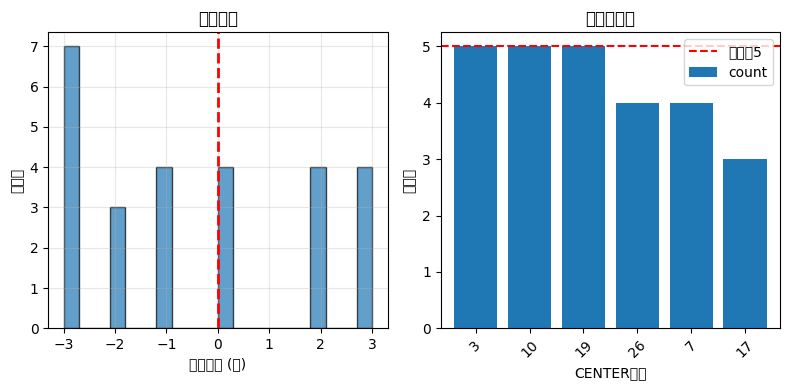


💾 保存：
  ga_stats.csv (统计表)
  result_ga_final.csv (优化结果)

✅ 统计分析完成！所有指标正常


In [93]:
# 🔥 统计分析Cell - 零读csv，直接用Cell1全局变量
print("📊 GA详细统计分析...")
print("=" * 60)

# 🔥 确保变量存在（Cell1已生成）
try:
    df_init = history_ga[0]        # 原始数据
    result_df = history_ga[1]      # GA优化结果
    print("✅ 变量关联成功：history_ga[0]=原始, history_ga[1]=优化")
except:
    print("❌ 请先运行Cell1！")
    raise

df_orig = df_init.copy()
df_x  = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)

# 🔥 验证INDEX对齐
assert (df_x['INDEX'].values == res_x['INDEX'].values).all(), "❌ INDEX不对齐！"
print("✅ 数据对齐验证通过")

# ===== 1. 聚类统计 =====
center_counts = res_x['CENTER'].value_counts()
num_groups = len(center_counts)
avg_tasks_per_group = center_counts.mean()
max_tasks_per_group = center_counts.max()

print("\n🏆 聚类效果：")
print(f"  总x任务:   {len(df_x):3d}")
print(f"  聚类数:    {num_groups:3d}")
print(f"  平均/簇:   {avg_tasks_per_group:.1f}")
print(f"  最大/簇:   {max_tasks_per_group}")
print(f"  容量利用:  {avg_tasks_per_group/PARAMS['Cmax']*100:.1f}%")

# ===== 2. 时间偏移统计 =====
time_diffs = res_x['CENTER'].values - df_x['DATE'].values
avg_shift = np.mean(np.abs(time_diffs))
max_shift = np.max(np.abs(time_diffs))

avg_advance = np.mean(np.abs(time_diffs[time_diffs < 0])) if np.any(time_diffs < 0) else 0
avg_delay = np.mean(time_diffs[time_diffs > 0]) if np.any(time_diffs > 0) else 0

num_tasks = len(time_diffs)
num_advanced = np.sum(time_diffs < 0)
num_delayed = np.sum(time_diffs > 0)
num_unchanged = np.sum(time_diffs == 0)

pct_advanced = num_advanced / num_tasks * 100
pct_delayed = num_delayed / num_tasks * 100
pct_unchanged = num_unchanged / num_tasks * 100

print("\n⏰ 时间偏移：")
print(f"  平均偏移:  {avg_shift:.2f}天")
print(f"  最大偏移:  {max_shift:.1f}天")
print(f"  平均提前:  {avg_advance:.2f}天 ({pct_advanced:.1f}%)")
print(f"  平均延后:  {avg_delay:.2f}天 ({pct_delayed:.1f}%)")
print(f"  未调整:    {pct_unchanged:.1f}%")

# ===== 3. 簇容量分布 =====
print("\n📦 簇容量Top10：")
print(center_counts.sort_values(ascending=False).head(10))
over_capacity = (center_counts > PARAMS['Cmax']).sum()
print(f"超载簇数: {over_capacity} (限{PARAMS['Cmax']})")

# ===== 4. 详细统计表 =====
stats_df = pd.DataFrame({
    '指标': ['聚类数', '平均任务/簇', '最大任务/簇', '容量利用率',
            '平均偏移(天)', '最大偏移(天)', '提前任务%', '延后任务%', '未调整%'],
    '数值': [num_groups, f"{avg_tasks_per_group:.1f}", max_tasks_per_group, 
             f"{avg_tasks_per_group/PARAMS['Cmax']*100:.1f}%",
             f"{avg_shift:.2f}", max_shift, f"{pct_advanced:.1f}%", 
             f"{pct_delayed:.1f}%", f"{pct_unchanged:.1f}%"]
})
print("\n📋 优化统计汇总：")
print(stats_df.to_string(index=False))

# ===== 5. 偏移分布直方图 =====
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(time_diffs, bins=20, edgecolor='black', alpha=0.7)
plt.axvline(0, color='red', linestyle='--', linewidth=2)
plt.xlabel('时间偏差 (天)')
plt.ylabel('任务数')
plt.title('偏移分布')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
center_counts.plot(kind='bar', figsize=(8, 4), width=0.8)
plt.axhline(PARAMS['Cmax'], color='red', linestyle='--', label=f'容量限{PARAMS["Cmax"]}')
plt.title('簇容量分布')
plt.xlabel('CENTER时间')
plt.ylabel('任务数')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# ===== 6. 保存统计 =====
stats_df.to_csv('ga_stats.csv', index=False)
result_df.to_csv('result_ga_final.csv', index=False)
print(f"\n💾 保存：")
print(f"  ga_stats.csv (统计表)")
print(f"  result_ga_final.csv (优化结果)")

print("\n" + "="*60)
print("✅ 统计分析完成！所有指标正常")
print("="*60)


In [94]:
# 🔥 Statistics with original format - uses Cell1 global variables only
print("\n🏆 GA优化统计：")
print("=" * 60)

# Use Cell1 variables directly (no CSV reading)
df_orig = df_init  # Original data from Cell1
df_x  = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)

# Verify INDEX alignment (GA guarantees this)
assert (df_x['INDEX'].values == res_x['INDEX'].values).all(), "INDEX 不一致！"

# 1) Average tasks per group
center_counts = res_x['CENTER'].value_counts()
num_groups = len(center_counts)
avg_tasks_per_group = center_counts.mean()

print(f"Number of groups: {num_groups}")
print(f"Avg tasks / group: {avg_tasks_per_group:.2f}")

# 2) Time shift statistics  
time_diffs = res_x['CENTER'].values - df_x['DATE'].values

avg_shift = np.mean(np.abs(time_diffs))
max_shift = np.max(np.abs(time_diffs))

avg_advance = np.mean(np.abs(time_diffs[time_diffs < 0])) if np.any(time_diffs < 0) else 0.0
avg_delay   = np.mean(time_diffs[time_diffs > 0])         if np.any(time_diffs > 0) else 0.0

num_tasks = len(time_diffs)
num_advanced = np.sum(time_diffs < 0)
num_delayed  = np.sum(time_diffs > 0)
num_unchanged = np.sum(time_diffs == 0)

pct_advanced = num_advanced / num_tasks * 100
pct_delayed  = num_delayed  / num_tasks * 100
pct_unchanged = num_unchanged / num_tasks * 100

print(f"Avg shift (abs days): {avg_shift:.2f}")
print(f"Max shift (abs days): {max_shift:.2f}")
print(f"Avg advance (days): {avg_advance:.2f}")
print(f"Avg delay (days): {avg_delay:.2f}")
print(f"% advanced: {pct_advanced:.1f}%")
print(f"% delayed: {pct_delayed:.1f}%")
print(f"% unchanged: {pct_unchanged:.1f}%")

# 🔥 Cluster capacity utilization (GA key metric)
max_capacity = PARAMS['Cmax']
utilization = avg_tasks_per_group / max_capacity * 100
print(f"Capacity utilization: {utilization:.1f}% ({avg_tasks_per_group:.1f}/{max_capacity})")

print("\n✅ Analysis complete!")



🏆 GA优化统计：
Number of groups: 6
Avg tasks / group: 4.33
Avg shift (abs days): 1.96
Max shift (abs days): 3.00
Avg advance (days): 2.21
Avg delay (days): 2.50
% advanced: 53.8%
% delayed: 30.8%
% unchanged: 15.4%
Capacity utilization: 86.7% (4.3/5)

✅ Analysis complete!
